In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings
warnings.filterwarnings('ignore')
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [2]:
df=pd.read_csv(r"C:\Users\Siddarood\Data Science 2\DS Morning 9th Feb 2026\DS Morning 9th Feb 2026\Non_linear_SVM_Dataset.csv")

In [3]:
df.shape

(500, 3)

In [4]:
df.head()

,X1,X2,Y
0,0.830858,-0.334342,1.0
1,0.991710,0.879000,0.0
2,1.107245,-0.470344,1.0
3,-0.140899,1.033148,0.0
4,0.405592,1.328529,0.0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      500 non-null    float64
 1   X2      500 non-null    float64
 2   Y       500 non-null    float64
dtypes: float64(3)
memory usage: 11.8 KB


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.isnull().sum()

X1    0
X2    0
Y     0
dtype: int64

In [8]:
df.describe()

,X1,X2,Y
count,500.000000,500.000000,500.000000
mean,0.518145,0.255367,0.500000
std,0.895432,0.543603,0.500501
min,-1.476127,-0.988526,0.000000
25%,-0.086818,-0.195163,0.000000
50%,0.479565,0.280467,0.500000
75%,1.122974,0.685076,1.000000
max,2.484802,1.504279,1.000000


<Axes: >

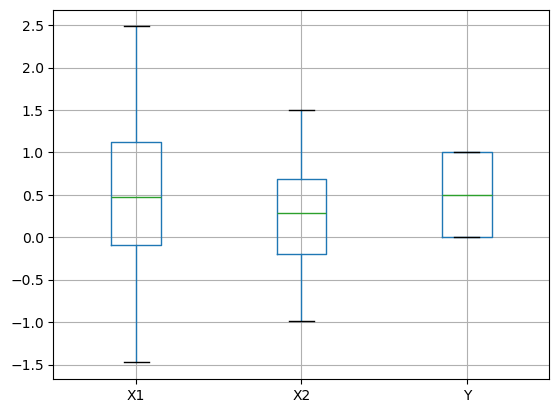

In [9]:
df.boxplot()

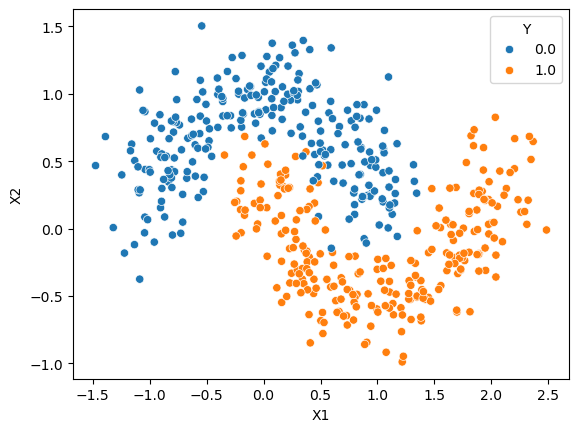

In [10]:
sns.scatterplot(data=df,x='X1',y='X2',hue=df.Y)# when we pass hue='Y'
# with respect to y column the graph is drwan 
plt.show()
# The above color dots are +Ve which is zero(0) which shown in graph
# and one is -Ve(1)

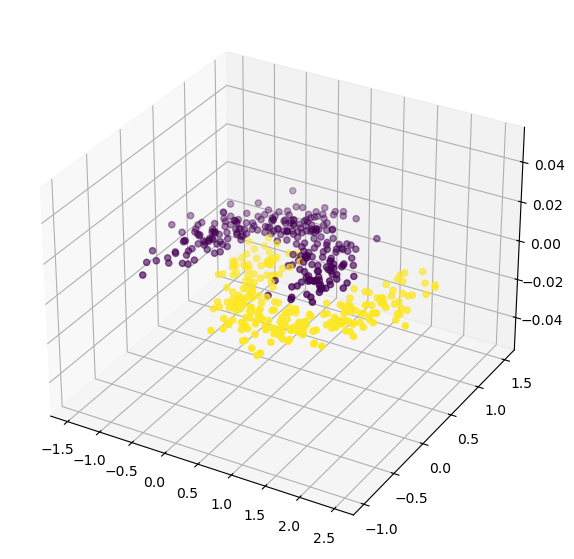

In [11]:
fig= plt.figure(figsize=(7,7))
ax= fig.add_subplot(111,projection='3d')
# Projection is for the 3d graph and 111 is for the size
ax.scatter(df.X1,df.X2,c=df.Y)
plt.show()
# Here C is the param which doing same function as "hue" in above code
# It will plot the 3D graph with respect to y and color the graph 

In [12]:
feature = df.drop(columns=['Y'])
target = df[['Y']]

In [13]:
x_train,x_test,y_train,y_test=train_test_split(feature,target,train_size=0.8,random_state=100,stratify=df.Y)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(400, 2)
(100, 2)
(400, 1)
(100, 1)


In [14]:
## Linear Kernal
linear_svc = SVC(kernel='linear')
linear_svc.fit(x_train,y_train)
y_pred=linear_svc.predict(x_test)
accuracy_score(y_test,y_pred)

0.81

In [15]:
# Poly Kernal
poly_svc=SVC(kernel='poly',degree=3,gamma=0.9)
poly_svc.fit(x_train,y_train)
y_pred1=poly_svc.predict(x_test)
accuracy_score(y_test, y_pred1)

0.88

In [16]:
# RBF
RBF_svc =SVC(kernel='rbf')
RBF_svc.fit(x_train,y_train)
y_pred= RBF_svc.predict(x_test)
accuracy_score(y_test,y_pred)

0.97

In [17]:
# Sigmoid Kernel
sigmoid_svc =SVC(kernel='sigmoid',gamma=0.1)
sigmoid_svc.fit(x_train,y_train)
y_pred= sigmoid_svc.predict(x_test)
accuracy_score(y_test,y_pred)

0.81

In [18]:
df.X1.min(),df.X1.max(),df.X2.min(),df.X2.max()

(-1.4761269392401806, 2.48480165010424, -0.9885260706545684, 1.504278803710552)

In [19]:
np.arange(1,2,0.1)

array([1. , 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9])

In [20]:
x1_min,x1_max,x2_min,x2_max=df.X1.min()-1,df.X1.max()+1,df.X2.min()-1,df.X2.max()+1
print(x1_min,x1_max,x2_min,x2_max)

-2.4761269392401806 3.48480165010424 -1.9885260706545684 2.5042788037105517


Here we are added the points on x.min and max to aviod the overlapping of the points on the boarder so by exteding the boarder boundary it the points will look good will not get overlap on the boders

In [21]:
h=0.02

The general inetrval value to create a mesh gird is "0.02" which create good visual graph.

In [22]:
xx,yy=np.meshgrid(np.arange(x1_min,x1_max,h),np.arange(x2_min,x2_max,h))
xx,yy

(array([[-2.47612694, -2.45612694, -2.43612694, ...,  3.44387306,
          3.46387306,  3.48387306],
        [-2.47612694, -2.45612694, -2.43612694, ...,  3.44387306,
          3.46387306,  3.48387306],
        [-2.47612694, -2.45612694, -2.43612694, ...,  3.44387306,
          3.46387306,  3.48387306],
        ...,
        [-2.47612694, -2.45612694, -2.43612694, ...,  3.44387306,
          3.46387306,  3.48387306],
        [-2.47612694, -2.45612694, -2.43612694, ...,  3.44387306,
          3.46387306,  3.48387306],
        [-2.47612694, -2.45612694, -2.43612694, ...,  3.44387306,
          3.46387306,  3.48387306]], shape=(225, 299)),
 array([[-1.98852607, -1.98852607, -1.98852607, ..., -1.98852607,
         -1.98852607, -1.98852607],
        [-1.96852607, -1.96852607, -1.96852607, ..., -1.96852607,
         -1.96852607, -1.96852607],
        [-1.94852607, -1.94852607, -1.94852607, ..., -1.94852607,
         -1.94852607, -1.94852607],
        ...,
        [ 2.45147393,  2.45147393,  

Here The code is creating the interval values for the meshgrid graph having the distance of 0.02 inertval gap next to each pts.

In [23]:
xx.ndim,yy.ndim

(2, 2)

In [24]:
xx.shape

(225, 299)

In [25]:
xx.shape

(225, 299)

In [26]:
yy.shape

(225, 299)

In [32]:
data = np.c_[np.ravel(xx),np.ravel(yy)]
data

array([[-2.47612694, -1.98852607],
       [-2.45612694, -1.98852607],
       [-2.43612694, -1.98852607],
       ...,
       [ 3.44387306,  2.49147393],
       [ 3.46387306,  2.49147393],
       [ 3.48387306,  2.49147393]], shape=(67275, 2))

* We trained our dataset in the column format. So to convert and save the pts into column, we are using the ravel function which will convert our each data into seprate pts. The but all the pt are in row form so to convert the row to column format "C_"  funtion will convert the row to data to column format.
* The left side data are xx pts and right side points are in the yy format.

In [36]:
z=linear_svc.predict(data)
z

array([1., 1., 1., ..., 0., 0., 0.], shape=(67275,))

* How to know our pts?
* We can see that -2.47 and -1.98 are and the output of when we passed to linear we see the first point data and linersvc out put when data is -2.47,-1.98 the output linear svc one and we can the (x2).max3.44 and (x1.max)2.49 is 0.
* Means the above points are zero and below are one  

In [38]:
z.ndim

1

* We trained our model into 2D form but our linear_svc output data in 1D so to get the seprated output graph we need convert the linear_svc data to 2D format then only we will get the output.

In [41]:
z1=z.reshape(xx.shape)
z1.ndim

2

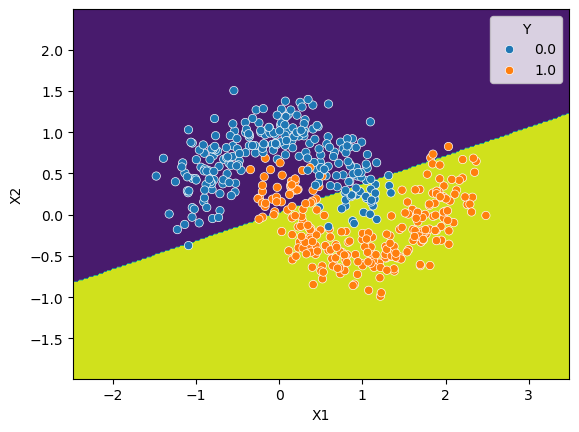

In [44]:
plt.contourf(xx,yy,z1)
sns.scatterplot(data=df,x='X1',y='X2',hue='Y')
plt.show()
# The above space is for class 'Zero' 
# below are for the class 'One'

<Figure size 500x500 with 0 Axes>

<Figure size 500x500 with 0 Axes>

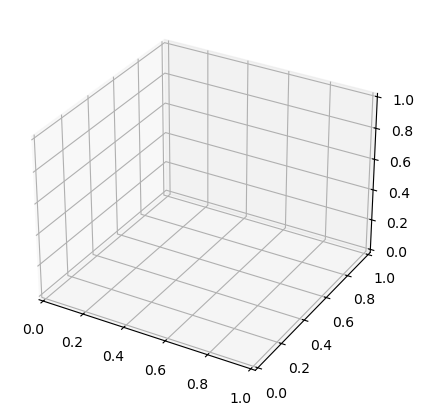

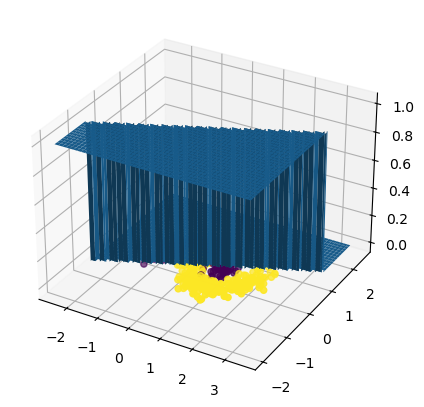

In [49]:
fig= plt.figure(figsize=(5,5))
ax= fig.add_subplot(111,projection='3d')
ax.scatter(df.X1,df.X2,c=df.Y)
ax.plot_surface(xx,yy,z1)
plt.show()

In [53]:
z2_=poly_svc.predict(data)
z2_

array([1., 1., 1., ..., 0., 0., 0.], shape=(67275,))

In [54]:
z2=z2_.reshape(xx.shape)
z2

array([[1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(225, 299))

In [55]:
z2.ndim

2

In [56]:
data

array([[-2.47612694, -1.98852607],
       [-2.45612694, -1.98852607],
       [-2.43612694, -1.98852607],
       ...,
       [ 3.44387306,  2.49147393],
       [ 3.46387306,  2.49147393],
       [ 3.48387306,  2.49147393]], shape=(67275, 2))

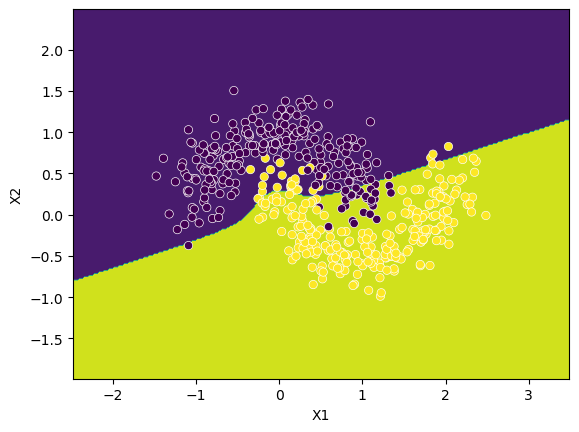

In [57]:
plt.contourf(xx,yy,z2)
sns.scatterplot(data=df,x='X1',y='X2',c=df.Y)
plt.show()

<Figure size 1000x1000 with 0 Axes>

<Figure size 1000x1000 with 0 Axes>

<Figure size 1000x1000 with 0 Axes>

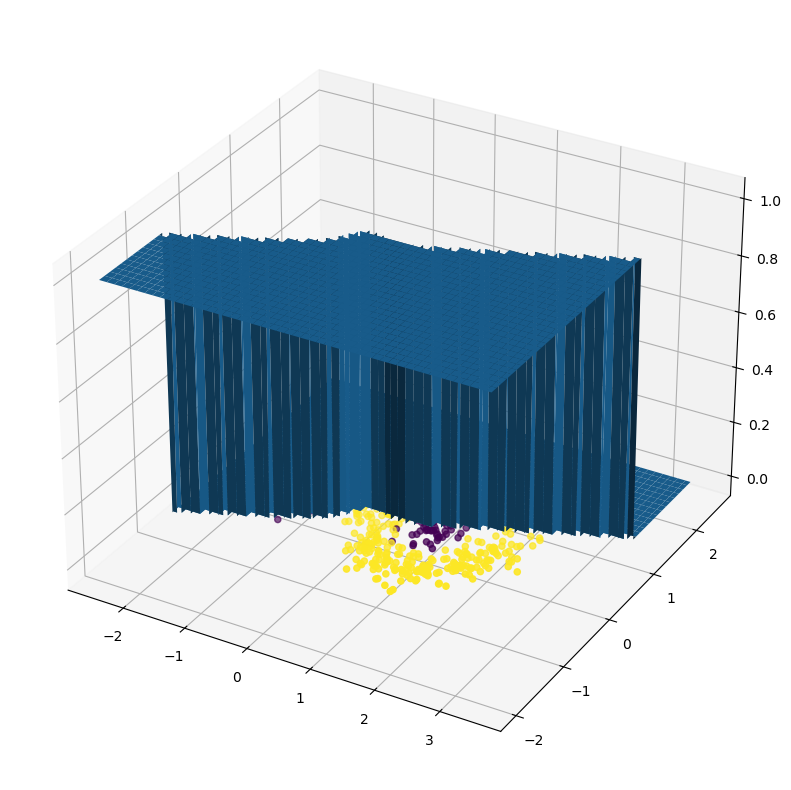

In [61]:
fig = plt.figure(figsize=(10,10))
ay= fig.add_subplot(111,projection='3d')
ay.scatter(df.X1,df.X2,c=df.Y)
ay.plot_surface(xx,yy,z2)
plt.show()

In [62]:
z3_ = RBF_svc.predict(data)
z3_

array([1., 1., 1., ..., 1., 1., 1.], shape=(67275,))

In [65]:
z3 = z3_.reshape(xx.shape)

In [66]:
data

array([[-2.47612694, -1.98852607],
       [-2.45612694, -1.98852607],
       [-2.43612694, -1.98852607],
       ...,
       [ 3.44387306,  2.49147393],
       [ 3.46387306,  2.49147393],
       [ 3.48387306,  2.49147393]], shape=(67275, 2))

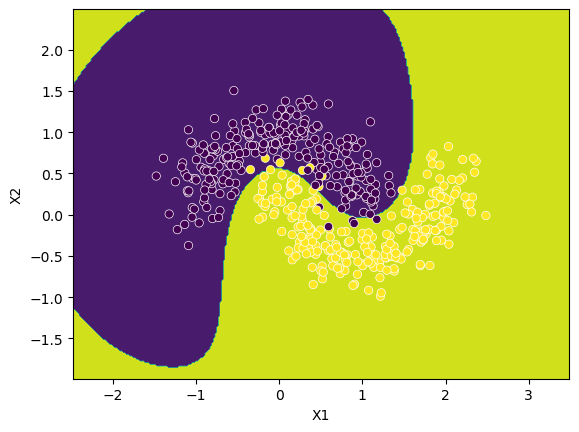

In [67]:
plt.contourf(xx,yy,z3)
sns.scatterplot(data=df,x='X1',y='X2',c=df.Y)
plt.show()

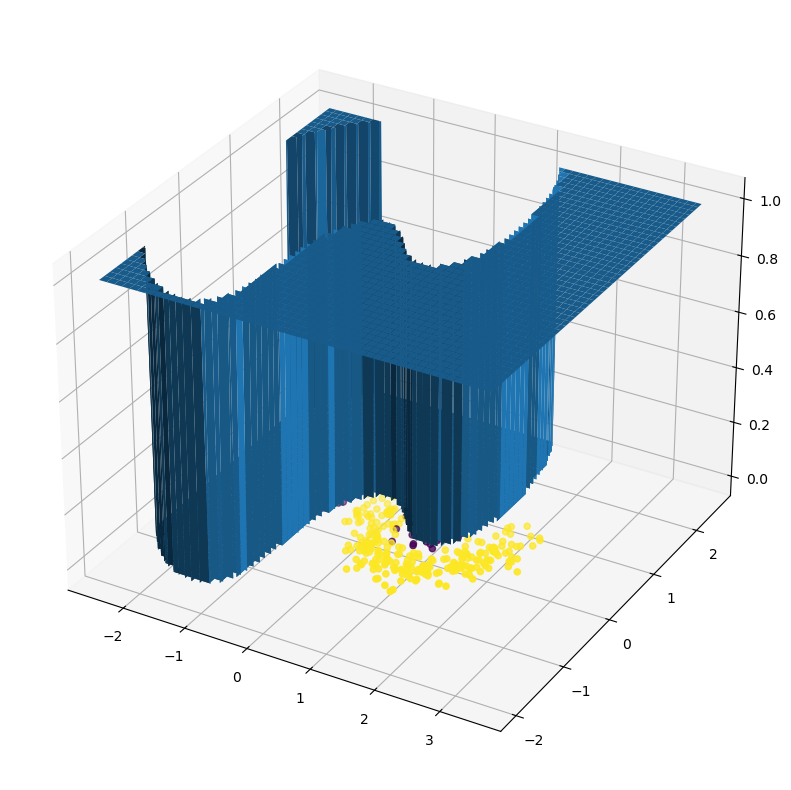

In [68]:
fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(111,projection='3d')
ax.scatter(df.X1,df.X2,c=df.Y)
ax.plot_surface(xx,yy,z3)
plt.show()

In [70]:
z4_= sigmoid_svc.predict(data)
z4_

array([1., 1., 1., ..., 0., 0., 0.], shape=(67275,))

In [71]:
data

array([[-2.47612694, -1.98852607],
       [-2.45612694, -1.98852607],
       [-2.43612694, -1.98852607],
       ...,
       [ 3.44387306,  2.49147393],
       [ 3.46387306,  2.49147393],
       [ 3.48387306,  2.49147393]], shape=(67275, 2))

In [72]:
z4 = z4_.reshape(xx.shape)
z4

array([[1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(225, 299))

In [73]:
z4.ndim

2

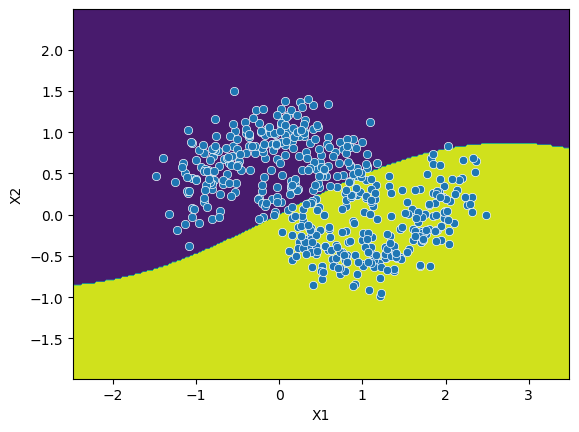

In [74]:
plt.contourf(xx,yy,z4)
sns.scatterplot(data=df,x='X1',y='X2')
plt.show()

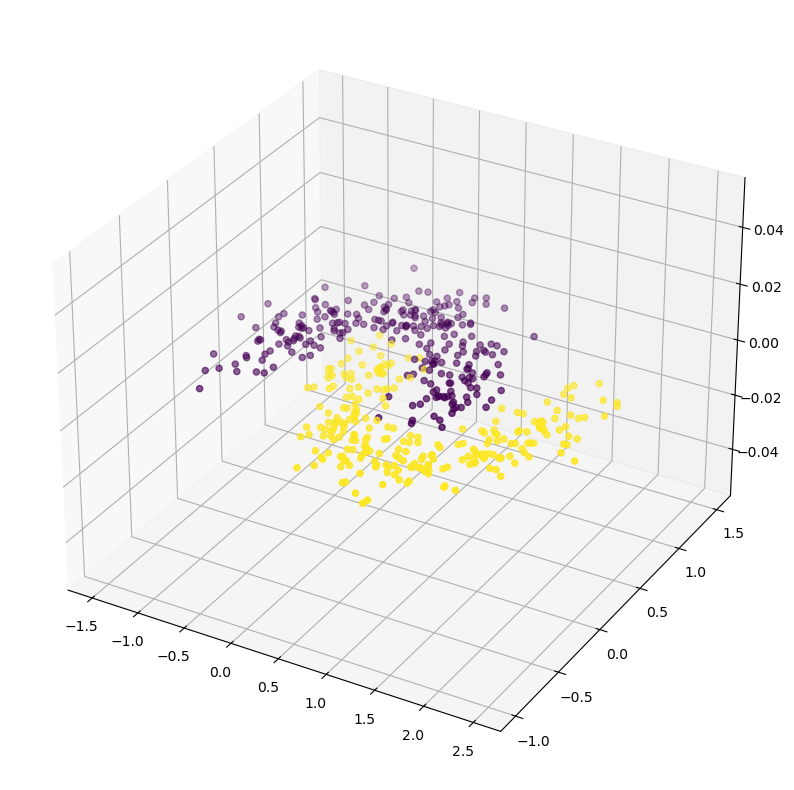

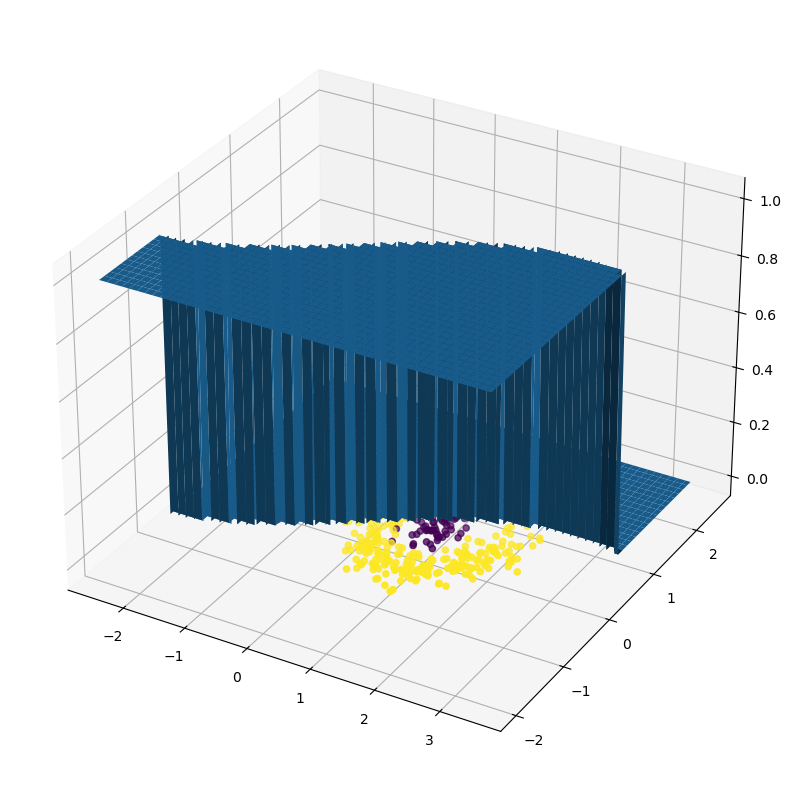

In [76]:
fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot(111,projection='3d')
ax.scatter(df.X1,df.X2,c=df.Y)
ax.plot_surface(xx,yy,z4)
plt.show()

* This graph is output of all the models.